Mounted at /content/drive
Dataset loaded successfully.
Features: 64, Samples: 23660

--- Target Classes Distribution ---
class
standingup     1772
sittingdown    1689
Name: count, dtype: int64


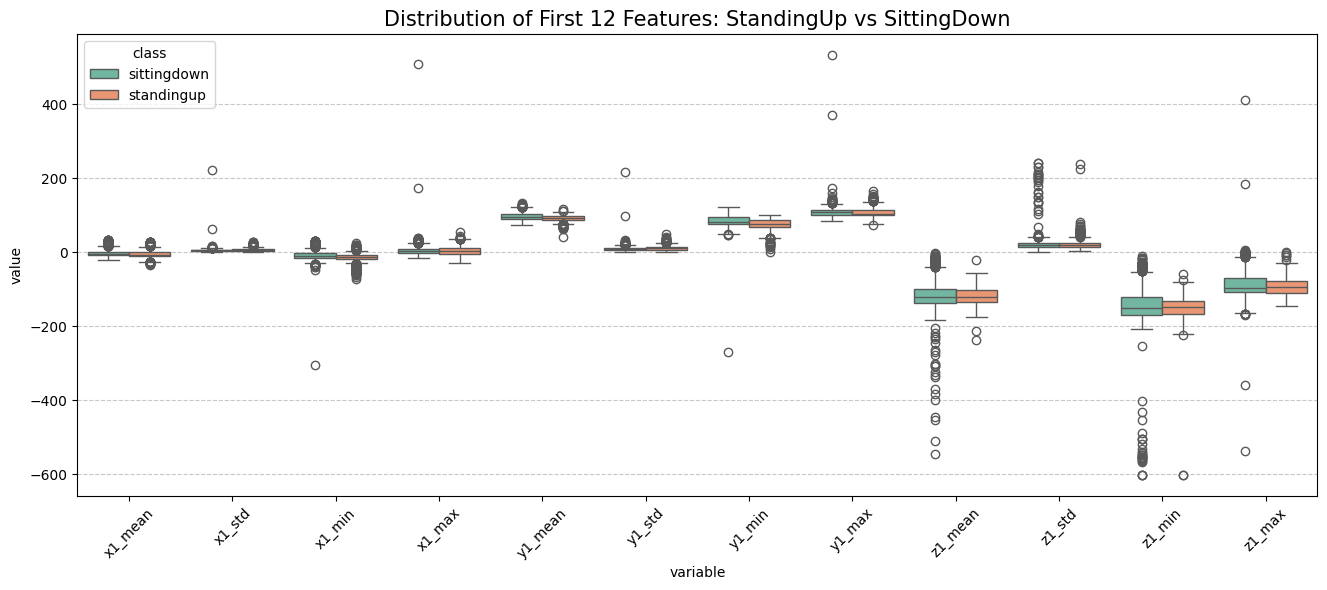

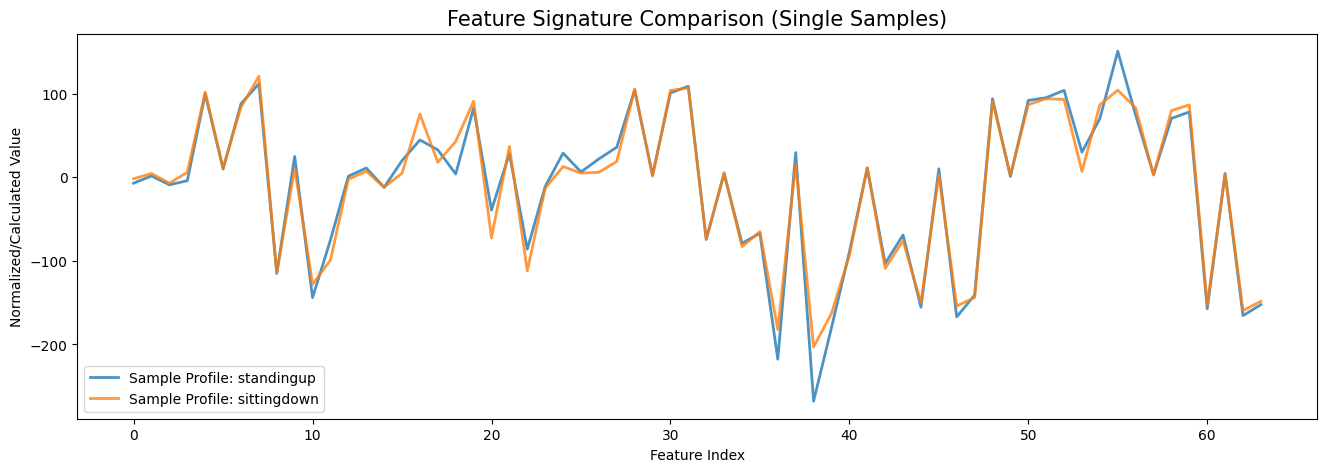

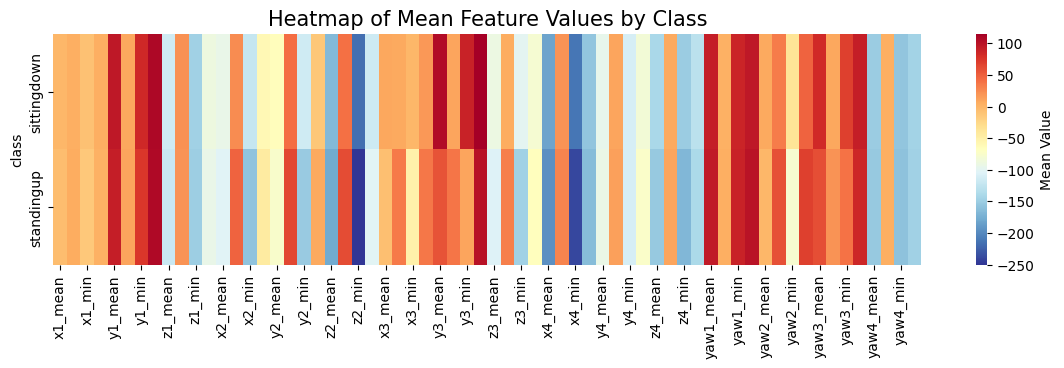

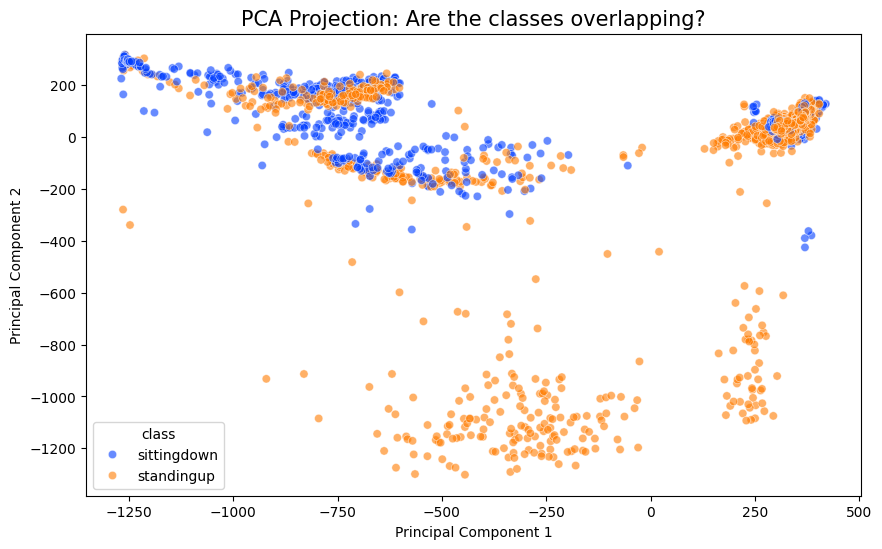


HAR DOMAIN ANALYSIS: WHY THE CONFUSION?
1. MIRROR MOVEMENTS: Standing up and Sitting down involve almost identical
   muscle groups and joint rotations but in reverse order.
2. STATICAL FEATURES: If the dataset uses features like Mean, Max, or Min
   within a window, the 'direction' of time is lost. Both actions have
   similar peaks in acceleration/angular velocity.
3. SENSOR LOCATION: Depending on the sensor position (e.g., waist vs pocket),
   the tilt of the device might look very similar for both transitions.
4. DURATION: Both activities are 'transient' (short-lived), unlike 'walking'
   which is periodic. This makes them harder to distinguish from noise.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut
from sklearn.decomposition import PCA
from collections import Counter

# --- 1. SETTINGS & DATA LOADING ---
drive.mount('/content/drive')
dataset_path = '/content/drive/MyDrive/Colab/windowed.csv'

try:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully.")

    # Basic check
    if 'class' in df.columns and 'user' in df.columns:
        X_windowed = df.drop(columns=['class', 'user'])
        y_windowed = df['class']
        groups = df['user']
        print(f"Features: {X_windowed.shape[1]}, Samples: {X_windowed.shape[0]}")
    else:
        print("Error: Missing 'class' or 'user' columns.")
        df = None
except FileNotFoundError:
    print(f"Error: File '{dataset_path}' not found.")
    df = None

# Proceed only if data is loaded
if df is not None:
    # --- 2. FOCUS ON CRITICAL CLASSES ---
    # We focus on the classes the model confuses most: 'standingup' and 'sittingdown'
    target_classes = ['standingup', 'sittingdown']
    df_filtered = df[df['class'].isin(target_classes)].copy()

    print("\n--- Target Classes Distribution ---")
    print(df_filtered['class'].value_counts())

    # --- 3. VISUALIZATION: FEATURE DISTRIBUTION (BOXPLOTS) ---
    # We select a subset of features to avoid overcrowding the plot
    # Change [0:12] to specific indices if you know which features are most relevant (e.g., Mean, Std)
    features_subset = X_windowed.columns[:12]

    plt.figure(figsize=(16, 6))
    df_melted = df_filtered.melt(id_vars='class', value_vars=features_subset)
    sns.boxplot(data=df_melted, x='variable', y='value', hue='class', palette='Set2')
    plt.xticks(rotation=45)
    plt.title("Distribution of First 12 Features: StandingUp vs SittingDown", fontsize=15)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    # --- 4. VISUALIZATION: SINGLE SAMPLE SIGNAL PROFILE ---
    # In HAR, a windowed sample is often a "signature" of the movement.
    # Let's plot the feature values as a line to see if the 'shape' is similar.
    plt.figure(figsize=(16, 5))
    for cls in target_classes:
        sample = df[df['class'] == cls].drop(columns=['class', 'user']).iloc[0]
        plt.plot(sample.values, label=f"Sample Profile: {cls}", alpha=0.8, linewidth=2)

    plt.title("Feature Signature Comparison (Single Samples)", fontsize=15)
    plt.xlabel("Feature Index")
    plt.ylabel("Normalized/Calculated Value")
    plt.legend()
    plt.show()

    # --- 5. VISUALIZATION: MEAN HEATMAP ---
    # Comparing the average feature vector for both classes
    plt.figure(figsize=(14, 3))
    avg_profiles = df_filtered.groupby('class').mean(numeric_only=True).drop(columns=['user'], errors='ignore')
    sns.heatmap(avg_profiles, cmap='RdYlBu_r', cbar_kws={'label': 'Mean Value'})
    plt.title("Heatmap of Mean Feature Values by Class", fontsize=15)
    plt.show()

    # --- 6. VISUALIZATION: 2D PROJECTION (PCA) ---
    # This helps see if the two classes are linearly separable or overlapping
    pca = PCA(n_components=2)
    X_subset = df_filtered.drop(columns=['class', 'user'])
    X_pca = pca.fit_transform(X_subset)

    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_filtered['class'], alpha=0.6, palette='bright')
    plt.title("PCA Projection: Are the classes overlapping?", fontsize=15)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.show()

    # --- 7. DOMAIN ANALYSIS SUMMARY (FOR YOUR REPORT) ---
    print("\n" + "="*50)
    print("HAR DOMAIN ANALYSIS: WHY THE CONFUSION?")
    print("="*50)
    print("1. MIRROR MOVEMENTS: Standing up and Sitting down involve almost identical")
    print("   muscle groups and joint rotations but in reverse order.")
    print("2. STATICAL FEATURES: If the dataset uses features like Mean, Max, or Min")
    print("   within a window, the 'direction' of time is lost. Both actions have")
    print("   similar peaks in acceleration/angular velocity.")
    print("3. SENSOR LOCATION: Depending on the sensor position (e.g., waist vs pocket),")
    print("   the tilt of the device might look very similar for both transitions.")
    print("4. DURATION: Both activities are 'transient' (short-lived), unlike 'walking'")
    print("   which is periodic. This makes them harder to distinguish from noise.")
    print("="*50)